# RLC Circuit Frequency Response

## Objective

This notebook investigates the frequency response of a series RLC circuit using the differential-equation concepts studied in Differential Equations for Engineers.

For a series RLC circuit, Kirchhoff's voltage law gives:

$$
L\frac{d^2q}{dt^2} + R\frac{dq}{dt} + \frac{1}{C}q = V(t)
$$

where:

- $q(t)$ is capacitor charge
- $\frac{dq}{dt}=i(t)$ is circuit current
- $L$ is inductance
- $R$ is resistance
- $C$ is capacitance
- $V(t)$ is the applied voltage

For sinusoidal forcing,

$$
V(t)=V_0\sin(2\pi ft)
$$

the circuit response depends strongly on the driving frequency $f$.

The undamped natural frequency, which is also the series-resonance frequency for this current response, is:

$$
f_0=\frac{1}{2\pi\sqrt{LC}}
$$

The goal is to numerically model the circuit and investigate how its response changes as the driving frequency moves through resonance.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Circuit parameters
R = 10          # resistance in ohms
L = 10e-3       # inductance: 10 mH
C = 1e-6        # capacitance: 1 microfarad

# Theoretical series-resonance frequency
f0 = 1 / (2 * np.pi * np.sqrt(L * C))

print(f"Theoretical series resonance: {f0:.2f} Hz")

Theoretical series resonance: 1591.55 Hz


## Converting the RLC Equation to a First-Order System

The series RLC equation is

$$
L\frac{d^2q}{dt^2}+R\frac{dq}{dt}+\frac{1}{C}q=V(t).
$$

Let

$$
i=\frac{dq}{dt}.
$$

Then the second-order equation can be written as two first-order equations:

$$
\frac{dq}{dt}=i
$$

and

$$
\frac{di}{dt}
=
\frac{V(t)-Ri-q/C}{L}.
$$

For a sinusoidal source,

$$
V(t)=V_0\sin(2\pi ft).
$$

This form allows the system to be solved numerically.

In [2]:
# Sinusoidal source amplitude
V0 = 1.0

def rlc_system(t, y, f):
    q, i = y

    voltage = V0 * np.sin(2 * np.pi * f * t)

    dqdt = i
    didt = (voltage - R * i - q / C) / L

    return [dqdt, didt]

In [3]:
def simulate_rlc(f, t_end=0.01):
    # Initial conditions:
    # q(0) = 0 C
    # i(0) = 0 A
    y0 = [0, 0]

    t_eval = np.linspace(0, t_end, 5000)

    solution = solve_ivp(
        rlc_system,
        [0, t_end],
        y0,
        t_eval=t_eval,
        args=(f,),
        rtol=1e-8,
        atol=1e-10
    )

    return solution.t, solution.y[0], solution.y[1]

## Time-Domain Response at Selected Frequencies

To illustrate the effect of resonance, the circuit is simulated at three driving frequencies: one below resonance, one near the theoretical series-resonance frequency, and one above resonance.

The current response is compared over time to show how strongly the circuit responds when the driving frequency approaches resonance.

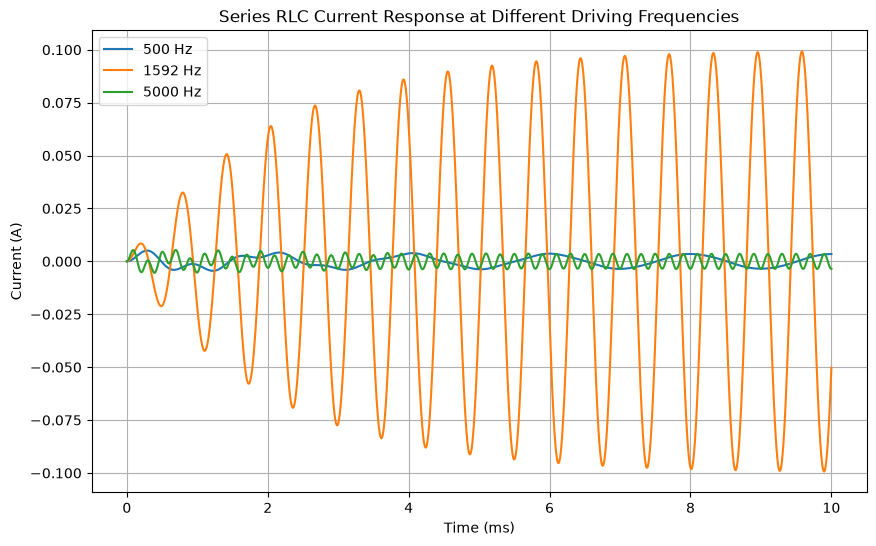

In [4]:
frequencies = [500, f0, 5000]

plt.figure(figsize=(10, 6))

for f in frequencies:
    t, q, i = simulate_rlc(f)

    plt.plot(
        t * 1000,
        i,
        label=f"{f:.0f} Hz"
    )

plt.xlabel("Time (ms)")
plt.ylabel("Current (A)")
plt.title("Series RLC Current Response at Different Driving Frequencies")
plt.legend()
plt.grid(True)

plt.savefig(
    "../results/rlc_time_response.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Frequency Sweep

To characterize the circuit more systematically, the driving frequency is varied across a range of values.

For each frequency, the circuit is simulated long enough for the initial transient to decay. The peak steady-state current is then measured.

This produces a frequency-response curve showing how strongly the circuit responds at each driving frequency.

In [5]:
# Sweep frequencies from 200 Hz to 5000 Hz
sweep_frequencies = np.linspace(200, 5000, 200)

peak_currents = []

for f in sweep_frequencies:
    # Simulate slightly longer so transient behavior can decay
    t, q, i = simulate_rlc(f, t_end=0.03)

    # Use only the final 20% of the simulation
    # to estimate steady-state current amplitude
    steady_start = int(0.8 * len(i))
    steady_current = i[steady_start:]

    peak_current = np.max(np.abs(steady_current))
    peak_currents.append(peak_current)

peak_currents = np.array(peak_currents)

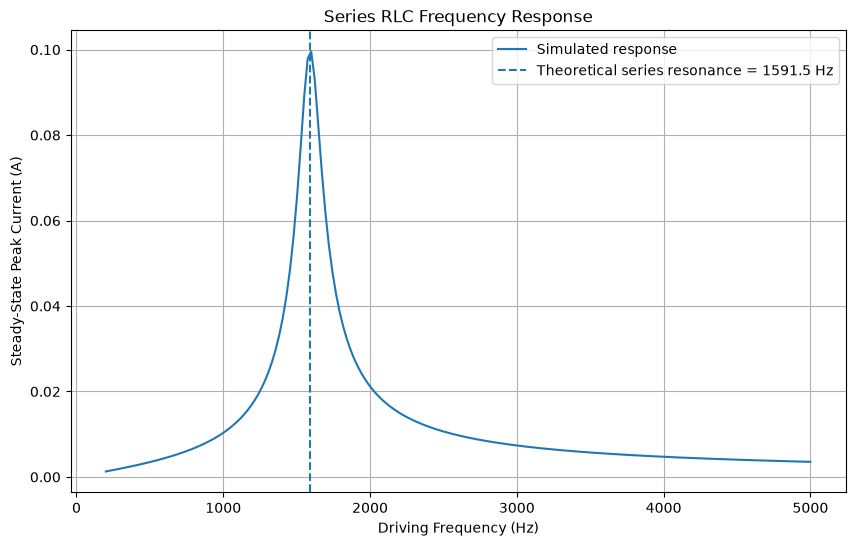

In [6]:
plt.figure(figsize=(10, 6))

plt.plot(
    sweep_frequencies,
    peak_currents,
    label="Simulated response"
)

plt.axvline(
    f0,
    linestyle="--",
    label=f"Theoretical series resonance = {f0:.1f} Hz"
)

plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Steady-State Peak Current (A)")
plt.title("Series RLC Frequency Response")
plt.grid(True)
plt.legend()

# Save the completed figure before displaying it
plt.savefig(
    "../results/rlc_frequency_response.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Refined Resonance Search

The broad frequency sweep identifies the approximate location of the maximum response. A second, higher-resolution sweep is then performed over a narrower frequency range centered on that observed maximum.

This provides a more precise numerical estimate of the series-resonance frequency for comparison with the theoretical prediction.

In [7]:
# Broad-sweep maximum
broad_max_index = np.argmax(peak_currents)
broad_resonant_frequency = sweep_frequencies[broad_max_index]
broad_maximum_current = peak_currents[broad_max_index]

# Refine the search around the broad-sweep maximum
fine_frequencies = np.linspace(
    broad_resonant_frequency - 100,
    broad_resonant_frequency + 100,
    401
)

fine_peak_currents = []

for f in fine_frequencies:
    t, q, i = simulate_rlc(f, t_end=0.03)

    # Ignore the initial transient and examine the final 20%
    steady_start = int(0.8 * len(i))
    steady_current = i[steady_start:]

    peak_current = np.max(np.abs(steady_current))
    fine_peak_currents.append(peak_current)

fine_peak_currents = np.array(fine_peak_currents)

fine_max_index = np.argmax(fine_peak_currents)

fine_resonant_frequency = fine_frequencies[fine_max_index]
fine_maximum_current = fine_peak_currents[fine_max_index]

print(f"Theoretical series resonance: {f0:.2f} Hz")
print(f"Broad-sweep maximum response: {broad_resonant_frequency:.2f} Hz")
print(f"Refined simulated resonance: {fine_resonant_frequency:.2f} Hz")
print(f"Refined maximum current: {fine_maximum_current:.5f} A")
print(f"Theoretical resonant current: {V0 / R:.5f} A")

Theoretical series resonance: 1591.55 Hz
Broad-sweep maximum response: 1598.99 Hz
Refined simulated resonance: 1591.49 Hz
Refined maximum current: 0.10000 A
Theoretical resonant current: 0.10000 A


## Validation and Results

For a series RLC circuit, the theoretical series-resonance frequency is

$$
f_0=\frac{1}{2\pi\sqrt{LC}}.
$$

For the selected circuit parameters,

$$
R=10\ \Omega,\qquad
L=10\text{ mH},\qquad
C=1\ \mu\text{F},
$$

the theoretical series-resonance frequency is approximately **1591.55 Hz**.

The broad numerical frequency sweep identified the region of maximum response. A second, higher-resolution sweep was then performed over a narrower frequency range centered on the maximum identified by the broad sweep.

The refined numerical sweep identified a maximum response at approximately **1591.49 Hz**, compared with the theoretical series-resonance frequency of **1591.55 Hz**. The two values differ by only about **0.004%**.

At series resonance, the inductive and capacitive reactances cancel:

$$
X_L = X_C.
$$

The net series impedance is therefore approximately the resistance alone, giving the theoretical peak current

$$
I_{\text{max}}
=
\frac{V_0}{R}
=
\frac{1}{10}
=
0.10000\text{ A}.
$$

The numerical simulation also produced a peak current of approximately **0.10000 A** at the displayed precision, in close agreement with the theoretical prediction.

The agreement between the differential-equation model, theoretical series-resonance calculation, and numerical simulation provides an initial validation of the circuit model. This experiment demonstrates how the governing differential equations of an electrical system can be used to predict and analyze its frequency-dependent behavior.